In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)

print("\nAll libraries imported successfully!")

NumPy version: 2.5.1
Pandas version: 2.2.3
Scikit-learn version: 1.9.0

All libraries imported successfully!


In [3]:
import pandas as pd

df = pd.read_csv(r"C:\Users\jaysa\OneDrive\Desktop\LIVE\data\train.csv")

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

df.head()

Dataset Shape: (7225, 11)

Column Names:
['CGPA', 'Internships', 'Projects', 'Workshops/Certifications', 'AptitudeTestScore', 'SoftSkillsRating', 'ExtracurricularActivities', 'PlacementTraining', 'SSC_Marks', 'HSC_Marks', 'PlacementStatus']


,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,ExtracurricularActivities,PlacementTraining,SSC_Marks,HSC_Marks,PlacementStatus
0,7.7,1,1,0,69,4.0,No,No,55,69,NotPlaced
1,7.6,2,3,1,80,4.3,Yes,Yes,57,70,NotPlaced
2,7.0,1,1,1,64,4.1,No,No,58,62,NotPlaced
3,7.9,1,3,2,90,4.8,Yes,Yes,82,80,Placed
4,6.7,0,2,1,71,3.7,No,No,55,67,NotPlaced


In [4]:
df.tail()

,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,ExtracurricularActivities,PlacementTraining,SSC_Marks,HSC_Marks,PlacementStatus
7220,7.4,0,1,0,65,3.4,No,No,55,62,NotPlaced
7221,7.5,1,1,0,84,4.2,No,Yes,56,69,NotPlaced
7222,8.2,1,3,2,90,4.7,Yes,Yes,65,84,Placed
7223,7.3,1,2,0,82,4.4,Yes,No,55,65,NotPlaced
7224,7.0,0,3,3,76,4.5,Yes,Yes,87,81,Placed


In [5]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nPlacement Status Distribution:")
print(df["PlacementStatus"].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7225 entries, 0 to 7224
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CGPA                       7225 non-null   float64
 1   Internships                7225 non-null   int64  
 2   Projects                   7225 non-null   int64  
 3   Workshops/Certifications   7225 non-null   int64  
 4   AptitudeTestScore          7225 non-null   int64  
 5   SoftSkillsRating           7225 non-null   float64
 6   ExtracurricularActivities  7225 non-null   object 
 7   PlacementTraining          7225 non-null   object 
 8   SSC_Marks                  7225 non-null   int64  
 9   HSC_Marks                  7225 non-null   int64  
 10  PlacementStatus            7225 non-null   object 
dtypes: float64(2), int64(6), object(3)
memory usage: 621.0+ KB

Missing Values:
CGPA                         0
Internships                  0
P

In [6]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nPlacement status counts:")
print(df["PlacementStatus"].value_counts())

print("\nPlacement status percentages:")
print(
    (df["PlacementStatus"].value_counts(normalize=True) * 100).round(2)
)

Missing values in each column:
CGPA                         0
Internships                  0
Projects                     0
Workshops/Certifications     0
AptitudeTestScore            0
SoftSkillsRating             0
ExtracurricularActivities    0
PlacementTraining            0
SSC_Marks                    0
HSC_Marks                    0
PlacementStatus              0
dtype: int64

Duplicate rows:
43

Placement status counts:
PlacementStatus
NotPlaced    4193
Placed       3032
Name: count, dtype: int64

Placement status percentages:
PlacementStatus
NotPlaced    58.03
Placed       41.97
Name: proportion, dtype: float64


In [7]:
df_clean = df.drop_duplicates().copy()

print("Original rows:", len(df))
print("Rows after removing duplicates:", len(df_clean))
print("Duplicates remaining:", df_clean.duplicated().sum())

Original rows: 7225
Rows after removing duplicates: 7182
Duplicates remaining: 0


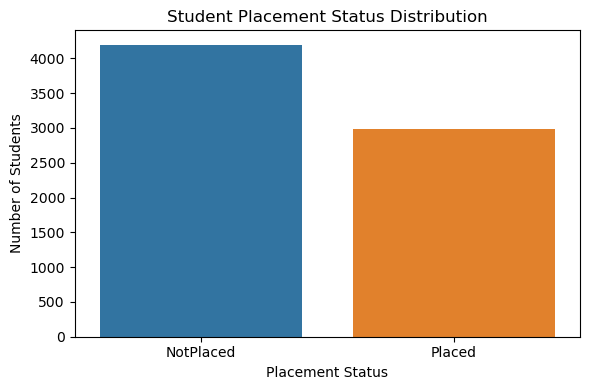

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df_clean,
    x="PlacementStatus",
    hue="PlacementStatus",
    legend=False
)

plt.title("Student Placement Status Distribution")
plt.xlabel("Placement Status")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

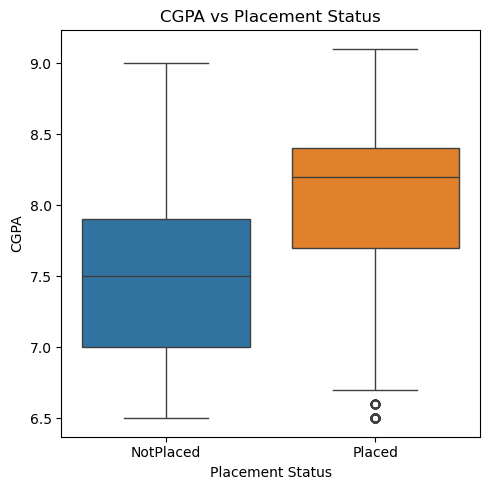

In [15]:
plt.figure(figsize=(5, 5))

sns.boxplot(
    data=df_clean,
    x="PlacementStatus",
    y="CGPA",
    hue="PlacementStatus",
    legend=False
)

plt.title("CGPA vs Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("CGPA")
plt.tight_layout()
plt.show()

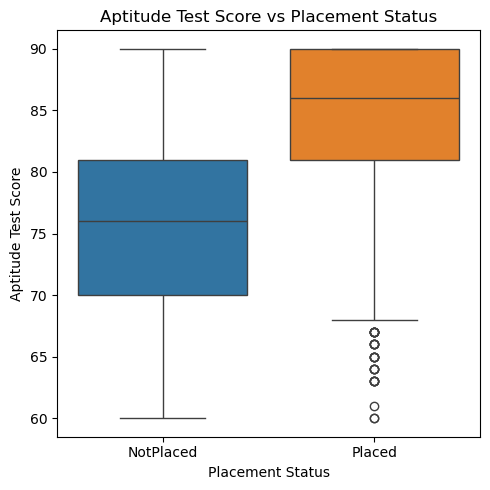

In [17]:
plt.figure(figsize=(5, 5))

sns.boxplot(
    data=df_clean,
    x="PlacementStatus",
    y="AptitudeTestScore",
    hue="PlacementStatus",
    legend=False
)

plt.title("Aptitude Test Score vs Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Aptitude Test Score")
plt.tight_layout()
plt.show()

In [18]:
print("Feature columns:")
X = df_clean.drop(columns=["PlacementStatus"])
print(X.columns.tolist())

print("\nTarget values:")
y = df_clean["PlacementStatus"]
print(y.value_counts())

print("\nFeature data types:")
print(X.dtypes)

Feature columns:
['CGPA', 'Internships', 'Projects', 'Workshops/Certifications', 'AptitudeTestScore', 'SoftSkillsRating', 'ExtracurricularActivities', 'PlacementTraining', 'SSC_Marks', 'HSC_Marks']

Target values:
PlacementStatus
NotPlaced    4192
Placed       2990
Name: count, dtype: int64

Feature data types:
CGPA                         float64
Internships                    int64
Projects                       int64
Workshops/Certifications       int64
AptitudeTestScore              int64
SoftSkillsRating             float64
ExtracurricularActivities     object
PlacementTraining             object
SSC_Marks                      int64
HSC_Marks                      int64
dtype: object


In [19]:
#Train Test Split
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns=["PlacementStatus"])
y = df_clean["PlacementStatus"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training features:", X_train.shape[1])
print("Testing target distribution:")
print(y_test.value_counts())

Training samples: 5745
Testing samples: 1437
Training features: 10
Testing target distribution:
PlacementStatus
NotPlaced    839
Placed       598
Name: count, dtype: int64


In [20]:
#Logistic Regression Model
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

logistic_model.fit(X_train, y_train)

y_pred_lr = logistic_model.predict(X_test)

print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test, y_pred_lr) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Logistic Regression Accuracy: 79.19 %

Classification Report:
              precision    recall  f1-score   support

   NotPlaced       0.81      0.83      0.82       839
      Placed       0.76      0.73      0.75       598

    accuracy                           0.79      1437
   macro avg       0.79      0.78      0.78      1437
weighted avg       0.79      0.79      0.79      1437


Confusion Matrix:
[[699 140]
 [159 439]]


In [21]:
#Random Forest Model
from sklearn.ensemble import RandomForestClassifier

rf_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

rf_model = Pipeline(
    steps=[
        ("preprocessor", rf_preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test, y_pred_lr) * 100, 2), "%")

print("Random Forest Accuracy:",
      round(accuracy_score(y_test, y_pred_rf) * 100, 2), "%")

print("\nRandom Forest Classification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nRandom Forest Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Logistic Regression Accuracy: 79.19 %
Random Forest Accuracy: 78.98 %

Random Forest Classification Report:
              precision    recall  f1-score   support

   NotPlaced       0.80      0.85      0.83       839
      Placed       0.77      0.70      0.74       598

    accuracy                           0.79      1437
   macro avg       0.79      0.78      0.78      1437
weighted avg       0.79      0.79      0.79      1437


Random Forest Confusion Matrix:
[[714 125]
 [177 421]]


In [22]:
from sklearn.metrics import classification_report

print("LOGISTIC REGRESSION")
print(classification_report(y_test, y_pred_lr))

print("\nRANDOM FOREST")
print(classification_report(y_test, y_pred_rf))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

   NotPlaced       0.81      0.83      0.82       839
      Placed       0.76      0.73      0.75       598

    accuracy                           0.79      1437
   macro avg       0.79      0.78      0.78      1437
weighted avg       0.79      0.79      0.79      1437


RANDOM FOREST
              precision    recall  f1-score   support

   NotPlaced       0.80      0.85      0.83       839
      Placed       0.77      0.70      0.74       598

    accuracy                           0.79      1437
   macro avg       0.79      0.78      0.78      1437
weighted avg       0.79      0.79      0.79      1437



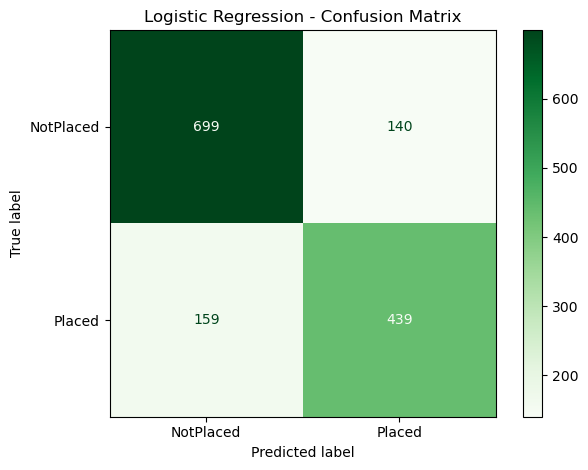

In [28]:
#Confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    labels=["NotPlaced", "Placed"],
    cmap="Greens"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

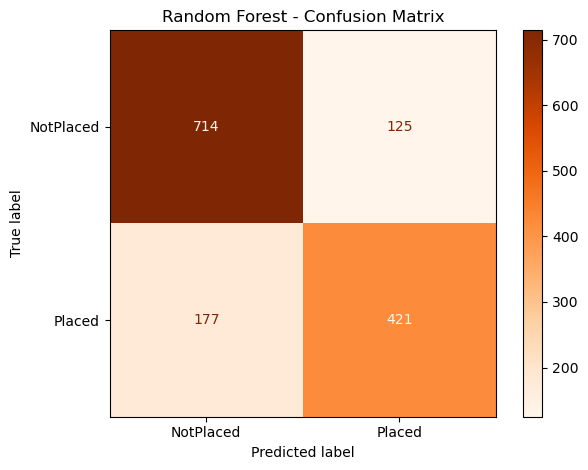

In [29]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    labels=["NotPlaced", "Placed"],
    cmap="Oranges"
)

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

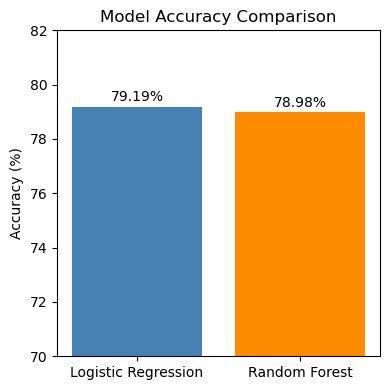

In [32]:
#Model Comparision chart
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [79.19, 78.98]
})

plt.figure(figsize=(4, 4))
bars = plt.bar(
    comparison["Model"],
    comparison["Accuracy"],
    color=["steelblue", "darkorange"]
)

plt.ylim(70, 82)
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy Comparison")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        f"{bar.get_height():.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [33]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(logistic_model, "../models/placement_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [34]:
import joblib
import os

model_path = "../models/placement_model.pkl"

loaded_model = joblib.load(model_path)

print("Model exists:", os.path.exists(model_path))
print("Model loaded successfully:", loaded_model is not None)
print("Model type:", type(loaded_model).__name__)

Model exists: True
Model loaded successfully: True
Model type: Pipeline


In [35]:
import pandas as pd

def predict_placement(
    cgpa,
    internships,
    projects,
    workshops,
    aptitude_score,
    soft_skills,
    extracurricular,
    placement_training,
    ssc_marks,
    hsc_marks
):
    student = pd.DataFrame([{
        "CGPA": cgpa,
        "Internships": internships,
        "Projects": projects,
        "Workshops/Certifications": workshops,
        "AptitudeTestScore": aptitude_score,
        "SoftSkillsRating": soft_skills,
        "ExtracurricularActivities": extracurricular,
        "PlacementTraining": placement_training,
        "SSC_Marks": ssc_marks,
        "HSC_Marks": hsc_marks
    }])

    prediction = loaded_model.predict(student)[0]
    probability = loaded_model.predict_proba(student)[0]

    classes = list(loaded_model.classes_)
    placed_index = classes.index("Placed")
    placed_probability = probability[placed_index] * 100

    return prediction, round(placed_probability, 2)

print("Prediction function created successfully!")

Prediction function created successfully!


In [36]:
#Sample Prediction Test
result, probability = predict_placement(
    cgpa=8.5,
    internships=0,
    projects=2,
    workshops=0,
    aptitude_score=75,
    soft_skills=4.2,
    extracurricular="Yes",
    placement_training="No",
    ssc_marks=75,
    hsc_marks=72
)

print("Predicted Placement Status:", result)
print("Estimated Placement Probability:", str(probability) + "%")

Predicted Placement Status: NotPlaced
Estimated Placement Probability: 24.64%


In [2]:
import sklearn 
print(sklearn.__version__)

1.9.0


In [3]:
import joblib
import sklearn

print("Notebook sklearn:", sklearn.__version__)
print("Model classes:", loaded_model.classes_)

Notebook sklearn: 1.9.0


NameError: name 'loaded_model' is not defined

In [4]:
import joblib
import sklearn
import os

model_path = r"C:\Users\jaysa\OneDrive\Desktop\LIVE\models\placement_model.pkl"

print("Scikit-learn version:", sklearn.__version__)
print("Model file exists:", os.path.exists(model_path))

loaded_model = joblib.load(model_path)

print("Model loaded successfully!")
print("Model classes:", loaded_model.classes_)

Scikit-learn version: 1.9.0
Model file exists: True
Model loaded successfully!
Model classes: ['NotPlaced' 'Placed']


In [5]:
print("Model type:", type(loaded_model).__name__)
print("Model version:", sklearn.__version__)
print("Features:", loaded_model.feature_names_in_)


Model type: Pipeline
Model version: 1.9.0
Features: ['CGPA' 'Internships' 'Projects' 'Workshops/Certifications'
 'AptitudeTestScore' 'SoftSkillsRating' 'ExtracurricularActivities'
 'PlacementTraining' 'SSC_Marks' 'HSC_Marks']


In [6]:
import pandas as pd

sample = pd.DataFrame([{
    "CGPA": 8.0,
    "Internships": 1,
    "Projects": 2,
    "Workshops/Certifications": 2,
    "AptitudeTestScore": 75,
    "SoftSkillsRating": 4,
    "ExtracurricularActivities": "Yes",
    "PlacementTraining": "Yes",
    "SSC_Marks": 80,
    "HSC_Marks": 75
}])

print("Prediction:", loaded_model.predict(sample)[0])
print("Probabilities:", loaded_model.predict_proba(sample)[0])

Prediction: NotPlaced
Probabilities: [0.52477595 0.47522405]
